# Hafta 3 · Model Ne Kadar İyi? Ezberlemek ve Öğrenmek

**Ekonomi ve Finansta Makine Öğrenmesi** · Prof. Dr. Mehmet Songur · Dicle Üniversitesi

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mehmetsongur/Machine-Learning-in-Economics-and-Finance/blob/main/code/Hafta03_Model_Basarisi.ipynb)

**Haftanın konusu:** Model başarısı: aşırı uyum, yanlılık-varyans, çapraz doğrulama, veri sızıntısı

Bu defter, Hafta 3 ders notundaki ve slaytlarındaki şu şekil ve tabloları üretir:

- **Şekil 1 ve tablo (2.1):** Aynı 30 gözleme üç farklı esneklikte polinom
- **Şekil 2 (2.2):** Esneklik ve hata: U biçimli eğri (300 tekrar)
- **Şekil 3 (3.1):** Yanlılık ve varyans: dart tahtası
- **Şekil 4 (3.1):** 25 farklı örneklemle eğitilmiş modeller
- **Tablo (4.2):** 5-katlı çapraz doğrulama
- **Şekil 6 (4.3):** Zaman serisinde rastgele ve zamana göre bölme

Tüm sayılar yapay (simüle edilmiş) veriye dayanır. Rastgele sayı üreticisinin tohumu sabit olduğu için hücreler **yukarıdan aşağıya sırayla** çalıştırıldığında sonuçlar ders materyalindeki değerlerle birebir aynı çıkar. Hücreleri atlarsanız ya da sırasını değiştirirseniz sayılar biraz farklılaşabilir; yorumlar değişmez.

Slaytlar: [Hafta 3 (PDF)](https://www.songurmehmet.com/assets/dersler/ml/Hafta03_Slaytlar.pdf)  
Kod MIT lisansıyla paylaşılmıştır; ayrıntı için deponun `code/LICENSE` dosyasına bakın.

## Ortak örnek: ücret ve deneyim

Mincer tipi bir ücret denklemi kuruyoruz: log ücret deneyimle önce artar, sonra düzleşir (ters U). Gerçek ilişkiyi biz belirliyoruz ve her bireyin ücretine rastgele bir sapma ekliyoruz. Bu dünyadan **30 kişilik bir eğitim örneklemi** ve **2.000 kişilik bir test örneklemi** çekiyoruz.

Tek aracımız **polinom regresyon**: log ücreti deneyimin 1., 2., …, d. dereceden terimleriyle en küçük karelerle kestiriyoruz. Polinom derecesi d, modelin esnekliğini ayarlayan düğmedir.

*Teknik not:* Deneyim (d/20 − 1) dönüşümüyle −1 ile 1 arasına taşınır. Bu, yüksek dereceli polinomlarda sayısal kararlılık içindir ve sonuçların yorumunu değiştirmez.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')   # yüksek dereceli polinomlarda çıkan uyarıları gizle

rng = np.random.default_rng(2026)          # tohum: sonuçlar ders notuyla aynı çıkar
SIG = 0.25                                  # gürültünün standart sapması → indirgenemez hata = 0,0625

def gercek(e):                              # gerçek ilişki (log ücret)
    return 2.0 + 0.08 * e - 0.0014 * e**2

def orneklem(n):                            # n kişilik örneklem çek
    e = rng.uniform(0, 40, n)                # deneyim (yıl)
    return e, gercek(e) + rng.normal(0, SIG, n)

def kur(e, y, d):  return np.polyfit(e / 20 - 1, y, d)      # d. dereceden polinomu EKK ile kestir
def ongor(k, e):   return np.polyval(k, e / 20 - 1)
def hko(a, b):     return float(np.mean((a - b) ** 2))       # hata kareleri ortalaması

e_egt, y_egt = orneklem(30)       # eğitim verisi
e_tst, y_tst = orneklem(2000)     # test verisi
izgara = np.linspace(0, 40, 400)

## 1. Aşırı uyum: aynı 30 gözlem, üç farklı esneklik (Şekil 1)

derece  1   eğitim hatası 0.102   test hatası 0.127
derece  2   eğitim hatası 0.070   test hatası 0.076
derece 12   eğitim hatası 0.032   test hatası 18.227


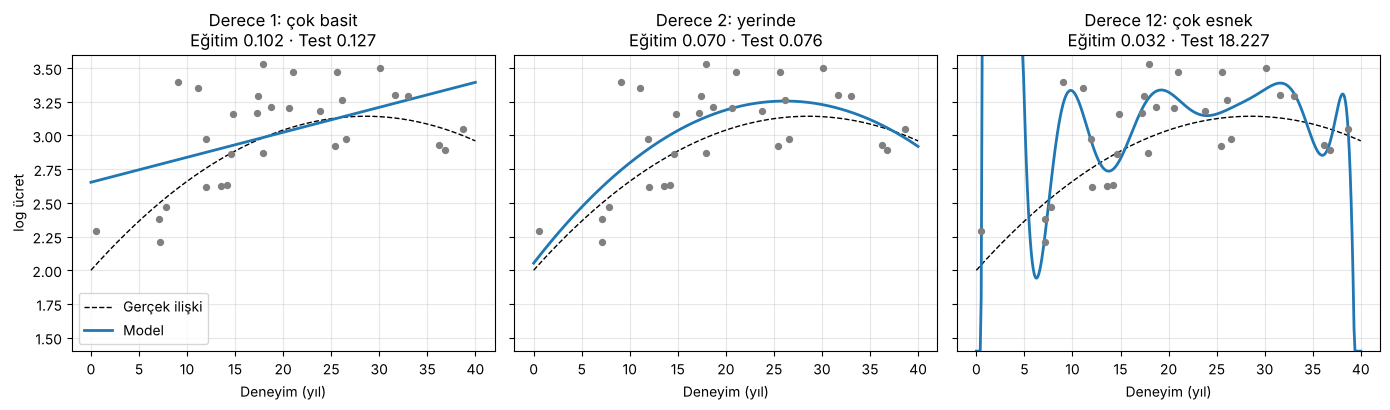

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, d, baslik in zip(axs, [1, 2, 12], ['Derece 1: çok basit', 'Derece 2: yerinde', 'Derece 12: çok esnek']):
    k = kur(e_egt, y_egt, d)
    egt, tst = hko(ongor(k, e_egt), y_egt), hko(ongor(k, e_tst), y_tst)
    print(f'derece {d:2d}   eğitim hatası {egt:.3f}   test hatası {tst:.3f}')
    ax.scatter(e_egt, y_egt, s=18, color='grey', zorder=3)
    ax.plot(izgara, gercek(izgara), '--', color='k', lw=1, label='Gerçek ilişki')
    ax.plot(izgara, np.clip(ongor(k, izgara), 1.4, 3.6), lw=2, label='Model')
    ax.set(title=f'{baslik}\nEğitim {egt:.3f} · Test {tst:.3f}', xlabel='Deneyim (yıl)', ylim=(1.4, 3.6)); ax.grid(alpha=0.3)
axs[0].set_ylabel('log ücret'); axs[0].legend()
plt.tight_layout(); plt.show()

Beklenen: derece 1 → 0,102 / 0,127; derece 2 → 0,070 / 0,076; derece 12 → 0,032 / 18,227. Derece 12’nin eğitim hatası en düşük, test hatası felaket: model gürültüyü ezberlemiş.

## 2. Esneklik ve hata: U biçimli eğri (Şekil 2)

Tek örneklem şansa bağlı olabilir. Deneyi 300 kez tekrarlayıp her derece için ortalama eğitim ve test hatasına bakıyoruz. (Bu hücre birkaç saniye sürebilir.)

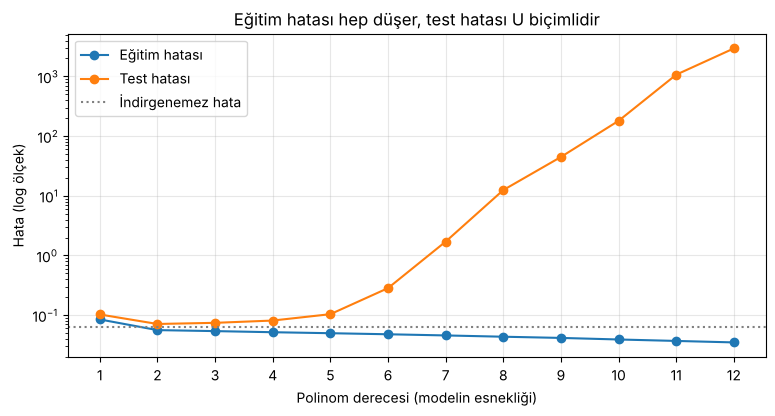

In [3]:
D = list(range(1, 13)); R = 300
EGT = np.zeros(12); TST = np.zeros(12)
for _ in range(R):
    e, y = orneklem(30)
    for i, d in enumerate(D):
        k = kur(e, y, d)
        EGT[i] += hko(ongor(k, e), y); TST[i] += hko(ongor(k, e_tst), y_tst)
EGT /= R; TST /= R

plt.figure(figsize=(9, 4.2))
plt.plot(D, EGT, 'o-', label='Eğitim hatası'); plt.plot(D, TST, 'o-', label='Test hatası')
plt.axhline(SIG**2, ls=':', color='grey', label='İndirgenemez hata')
plt.yscale('log'); plt.xticks(D); plt.grid(alpha=0.3); plt.legend()
plt.xlabel('Polinom derecesi (modelin esnekliği)'); plt.ylabel('Hata (log ölçek)')
plt.title('Eğitim hatası hep düşer, test hatası U biçimlidir'); plt.show()

## 3. Yanlılık ve varyans

### Dart tahtası benzetmesi (Şekil 3)

Merkez gerçek değerdir; her nokta, farklı bir örneklemle eğitilmiş modelin öngörüsüdür. Bu şekil yalnızca bir çizimdir, ama rastgele sayı kullandığı için sonraki hücrelerin ders notuyla aynı sonucu vermesi için atlanmamalıdır.

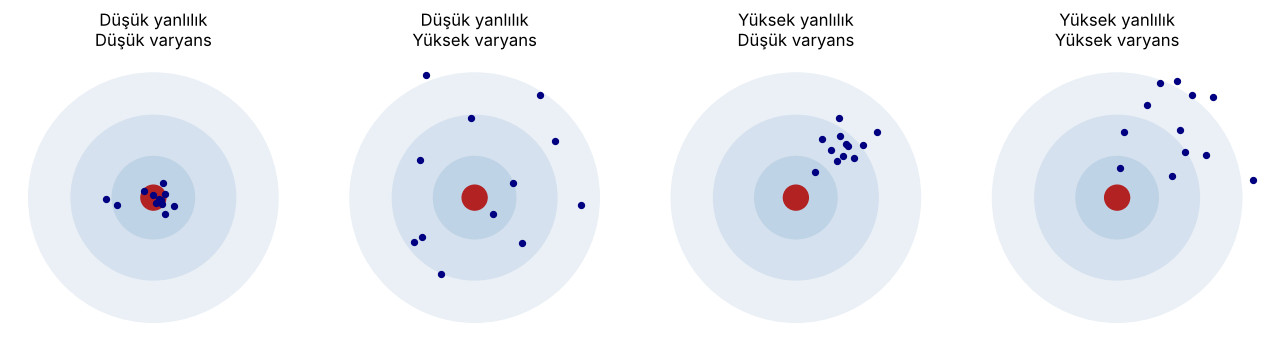

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
ayar = [('Düşük yanlılık\nDüşük varyans', 0, 0.12), ('Düşük yanlılık\nYüksek varyans', 0, 0.42),
        ('Yüksek yanlılık\nDüşük varyans', 0.55, 0.12), ('Yüksek yanlılık\nYüksek varyans', 0.55, 0.42)]
for ax, (baslik, yanlilik, varyans) in zip(axs, ayar):
    for r, c in [(1, '#EAF0F6'), (0.66, '#D5E1EE'), (0.33, '#BFD3E6'), (0.1, 'firebrick')]:
        ax.add_patch(plt.Circle((0, 0), r, color=c, zorder=1))
    p = rng.normal(0, varyans, (12, 2)) + [yanlilik * 0.7, yanlilik * 0.7]
    ax.scatter(p[:, 0], p[:, 1], s=18, color='navy', zorder=3)
    ax.set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), title=baslik); ax.set_aspect('equal'); ax.axis('off')
plt.tight_layout(); plt.show()

### Aynı fikir, ücret örneğinde (Şekil 4)

25 farklı 30 kişilik örneklemle eğitilmiş modeller. Derece 1: hep benzer ama hep yanlış (yüksek yanlılık, düşük varyans). Derece 12: ortalamada gerçek ilişkinin etrafında ama her örneklemde bambaşka (düşük yanlılık, yüksek varyans).

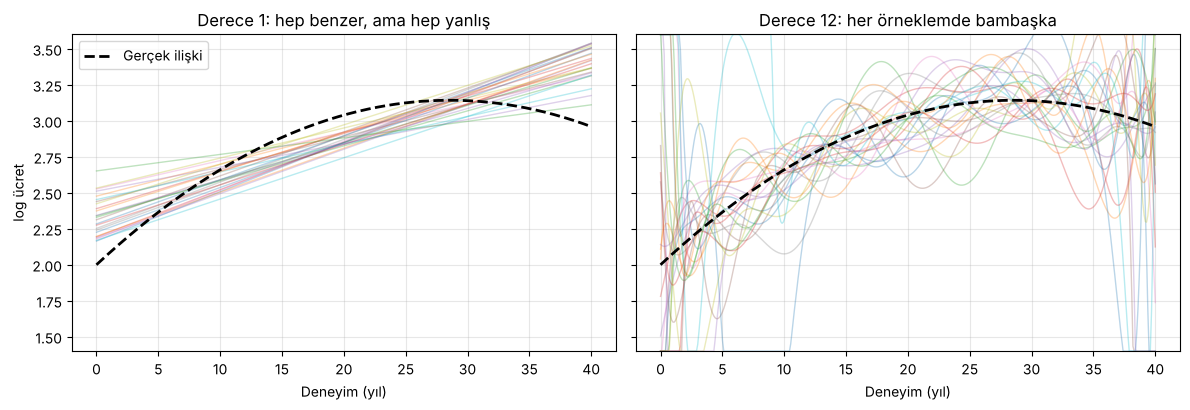

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, d, baslik in [(axs[0], 1, 'Derece 1: hep benzer, ama hep yanlış'), (axs[1], 12, 'Derece 12: her örneklemde bambaşka')]:
    for _ in range(25):
        e, y = orneklem(30)
        ax.plot(izgara, np.clip(ongor(kur(e, y, d), izgara), 1.4, 3.6), alpha=0.3, lw=1)
    ax.plot(izgara, gercek(izgara), '--', color='k', lw=2, label='Gerçek ilişki')
    ax.set(title=baslik, xlabel='Deneyim (yıl)', ylim=(1.4, 3.6)); ax.grid(alpha=0.3)
axs[0].set_ylabel('log ücret'); axs[0].legend()
plt.tight_layout(); plt.show()

## 4. 5-katlı çapraz doğrulama (tablo, 4.2)

Test verisine hiç bakmadan polinom derecesini seçiyoruz. 30 kişilik eğitim verisini beş kata bölüyor, her turda bir katı doğrulama için ayırıyor, modeli kalan dört katla kuruyoruz.

In [6]:
k = 5
katlar = np.array_split(rng.permutation(30), k)
print('derece   eğitim hatası   çapraz doğrulama hatası   test hatası (2.000 yeni kişi)')
for d in range(1, 9):
    hatalar = []
    for i in range(k):
        dog = katlar[i]
        egt = np.concatenate([katlar[j] for j in range(k) if j != i])
        hatalar.append(hko(ongor(kur(e_egt[egt], y_egt[egt], d), e_egt[dog]), y_egt[dog]))
    model = kur(e_egt, y_egt, d)
    print(f'{d:6d}   {hko(ongor(model, e_egt), y_egt):13.3f}   {np.mean(hatalar):23.3f}   {hko(ongor(model, e_tst), y_tst):12.3f}')

derece   eğitim hatası   çapraz doğrulama hatası   test hatası (2.000 yeni kişi)
     1           0.102                     0.140          0.127
     2           0.070                     0.075          0.076
     3           0.069                     0.118          0.078
     4           0.068                     0.134          0.077
     5           0.068                     0.418          0.077
     6           0.066                     2.644          0.079
     7           0.066                   281.645          0.079
     8           0.043                  1451.363          1.259


Beklenen: çapraz doğrulama hatası derece 2’de en düşük (0,075); eğitim hatasına bakan biri ise en esnek modeli seçerdi. Küçük örneklemde çapraz doğrulama hatası gürültülüdür (derece 3–6’nın test hatası derece 2’ye yakın, ama çapraz doğrulama onları olduğundan kötü gösteriyor); yine de modelleri sıralamaya ve iyi olanı seçmeye hizmet eder.

## 5. Zaman serisinde rastgele bölme geleceği gösterir (Şekil 6)

Rassal yürüyüş izleyen 200 aylık yapay bir seri (kur ya da hisse fiyatına benzer) ve son derece basit bir model: bir ayın değerini, eğitim verisinde zaman olarak ona en yakın ayın değeriyle öngör. Aynı modeli iki farklı bölmeyle değerlendiriyoruz. Bu bölüm ayrı bir rastgele sayı üreticisi kullanır.

Rastgele bölme     test hatası (kök HKO): 0.78
Zamana göre bölme  test hatası (kök HKO): 9.13


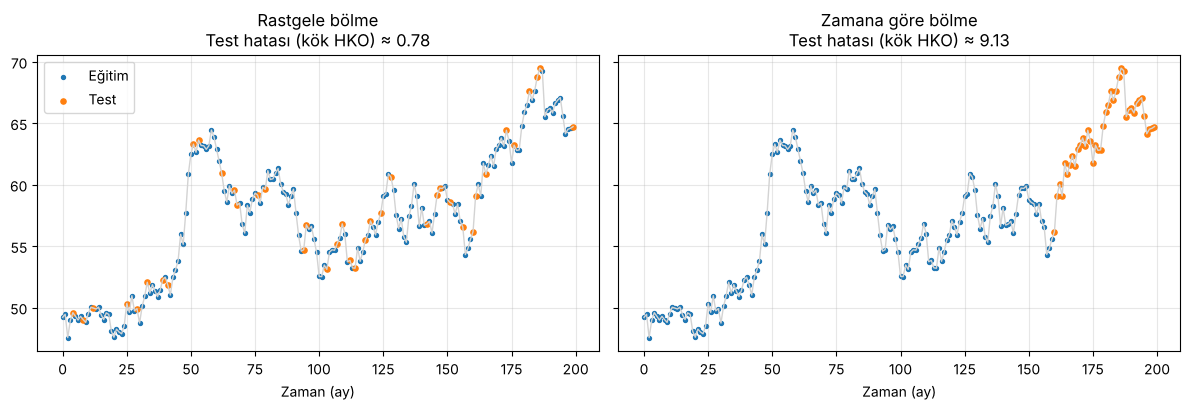

In [7]:
rng2 = np.random.default_rng(2026)
T = 200
seri = np.cumsum(rng2.normal(size=T)) + 50     # rassal yürüyüş
zaman = np.arange(T)

def en_yakin_ay(egitim, test):
    egitim = np.array(sorted(egitim))
    return np.array([seri[egitim[np.argmin(np.abs(egitim - t))]] for t in test])

def kok_hko(egitim, test): return np.sqrt(np.mean((en_yakin_ay(egitim, test) - seri[test]) ** 2))

karisik = rng2.permutation(T)
bolmeler = {'Rastgele bölme': (np.sort(karisik[40:]), np.sort(karisik[:40])),
            'Zamana göre bölme': (np.arange(160), np.arange(160, 200))}

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (ad, (egt, tst)) in zip(axs, bolmeler.items()):
    h = kok_hko(egt, tst); print(f'{ad:18s} test hatası (kök HKO): {h:.2f}')
    ax.plot(zaman, seri, color='lightgrey', lw=1)
    ax.scatter(egt, seri[egt], s=8, label='Eğitim'); ax.scatter(tst, seri[tst], s=14, label='Test')
    ax.set(title=f'{ad}\nTest hatası (kök HKO) ≈ {h:.2f}', xlabel='Zaman (ay)'); ax.grid(alpha=0.3)
axs[0].legend(); plt.tight_layout(); plt.show()

Beklenen: rastgele bölmede ≈ 0,78, zamana göre bölmede ≈ 9,13. Rastgele bölmede model test ayının sonrasını da görmüştür, yani geleceği bilmektedir. **Zaman serisinde geçmişle eğit, gelecekle doğrula.**

## Kendiniz deneyin

Seriyi rassal yürüyüş yerine bağımsız gürültüyle üretin: yukarıdaki hücrede `seri = rng2.normal(size=T) + 50` yazıp yeniden çalıştırın. Gözlemler birbirinden bağımsız olduğunda iki bölmenin hatası birbirine yaklaşır: sorunun kaynağı bağımlılıktır.